# Ames 房价预测｜第二轮模型比较

用 1,460 笔有成交价的交易检验对房价估计的改动，给竞赛测试集的 1,459 套房定价。主指标是原项目相同五折的平均 Log RMSE。还将逐房计算第 90 百分位误差，并在选定方案后，单独用 2006–2009 年训练、2010 年验证。

Notebook 可从第一格顺序执行。前三张图展示训练数据，后三张图检查模型比较、难例和残差。随附 README 列出复现步骤及参考实现。

In [1]:
import hashlib
import io
import os
import zipfile
from importlib.metadata import version
from pathlib import Path
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
OUT = Path(os.environ.get("HOUSE_PRICES_OUTPUT_DIR", "."))
FIGURES = OUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

print("  |  ".join(f"{p} {version(p)}" for p in ("numpy", "pandas", "scikit-learn", "catboost", "matplotlib")))

numpy 2.5.3  |  pandas 3.1.1  |  scikit-learn 1.9.1  |  catboost 1.2.10  |  matplotlib 3.11.2


## 数据和文件校验

Kaggle 上可直接运行全部单元格。本地优先查找 `data/`，也可通过 `HOUSE_PRICES_DATA_DIR` 指定包含三个原始 CSV 的目录。首次运行时若缺少本地文件，代码会下载固定版本的公开数据集。三个文件分别校验 SHA-256，以免误读全量 Ames 数据或其他竞赛的同名文件。

In [2]:
FILES = {
    "train.csv": "1e18addf81e5e4d347cc17ee6075bbe4a42b7fa26b9e5b063e8f692a5f929d41",
    "test.csv": "8fdd3d829d4d986b58f845c9553b225e67dd8383624d90fb6ca1d4bed5798c1e",
    "sample_submission.csv": "f19e99699b925aa3085c8d2ae43c62f15fbcd35e4a953b98025f8392c3ffa807",
}
PUBLIC_ARCHIVE = (
    "https://www.kaggle.com/api/v1/datasets/download/"
    "shadalishah/house-prices-advanced-regression-techniques?datasetVersionNumber=1"
)


def checked_bytes(name, content):
    normalized = content.replace(b"\r\n", b"\n")
    if hashlib.sha256(normalized).hexdigest() != FILES[name]:
        raise ValueError(f"{name} 的校验值不符，请检查数据来源。")
    return normalized


def read_inputs():
    custom_path = os.environ.get("HOUSE_PRICES_DATA_DIR")
    if custom_path:
        roots = [Path(custom_path)]
    else:
        roots = [Path("data")]
        mount = Path("/kaggle/input")
        if mount.is_dir():
            roots += sorted(p.parent for p in mount.rglob("sample_submission.csv"))
    for root in roots:
        if all((root / name).is_file() for name in FILES):
            return {name: checked_bytes(name, (root / name).read_bytes()) for name in FILES}
    if custom_path:
        raise FileNotFoundError("指定的数据目录应同时包含 train.csv、test.csv 和 sample_submission.csv。")
    request = Request(PUBLIC_ARCHIVE, headers={"User-Agent": "Ames-House-Prices/1.0"})
    with urlopen(request, timeout=60) as response:
        with zipfile.ZipFile(io.BytesIO(response.read())) as archive:
            return {name: checked_bytes(name, archive.read(name)) for name in FILES}


raw_inputs = read_inputs()
train = pd.read_csv(io.BytesIO(raw_inputs["train.csv"]))
test = pd.read_csv(io.BytesIO(raw_inputs["test.csv"]))
sample = pd.read_csv(io.BytesIO(raw_inputs["sample_submission.csv"]))
assert train.shape == (1460, 81) and test.shape == (1459, 80)
assert train.drop(columns="SalePrice").columns.equals(test.columns)
assert list(sample.columns) == ["Id", "SalePrice"] and test["Id"].equals(sample["Id"])
assert train["Id"].is_unique and test["Id"].is_unique and not train["Id"].isin(test["Id"]).any()
y = train["SalePrice"].astype(float)
assert (np.isfinite(y) & y.gt(0)).all()
print(f"训练集 {len(train):,} 笔，测试集 {len(test):,} 套，每套房有 {test.shape[1]-1} 个原始特征。")

训练集 1,460 笔，测试集 1,459 套，每套房有 79 个原始特征。


## 成交价、缺失值和居住面积

前三张图只使用训练集。房价分布展示预测目标的尺度。缺失比例决定预处理方法。面积与房价的散点图帮助识别容易估错的交易。

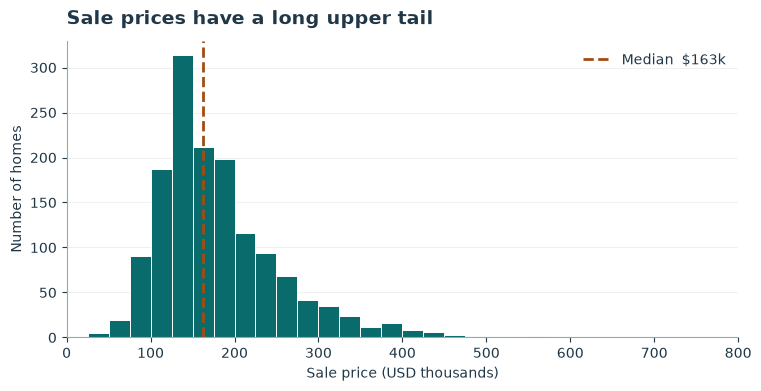

成交价中位数为 $163,000，第 90 百分位为 $278,000。后续模型拟合自然对数房价。


In [3]:
INK = "#203747"
TEAL = "#096b6c"
AMBER = "#a34c12"
MUTED = "#637986"
PALE = "#b9d5d3"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 14,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#9aa8aa",
    "axes.axisbelow": True, "figure.facecolor": "white", "savefig.facecolor": "white",
})


def show_figure(fig, name):
    fig.savefig(FIGURES / name, dpi=150, bbox_inches="tight", pad_inches=0.15)
    plt.show()
    plt.close(fig)


fig, ax = plt.subplots(figsize=(7.5, 3.8), layout="constrained")
price_k = y / 1000
ax.hist(price_k, bins=np.arange(0, price_k.max() + 25, 25), color=TEAL, edgecolor="white", linewidth=0.7)
ax.axvline(price_k.median(), color=AMBER, linestyle="--", linewidth=2,
           label=f"Median  ${price_k.median():,.0f}k")
ax.set(xlabel="Sale price (USD thousands)", ylabel="Number of homes", title="Sale prices have a long upper tail", xlim=(0, 800))
ax.grid(axis="y", alpha=0.18)
ax.legend(frameon=False)
show_figure(fig, "01_sale_price.png")
print(f"成交价中位数为 ${y.median():,.0f}，第 90 百分位为 ${y.quantile(.9):,.0f}。后续模型拟合自然对数房价。")

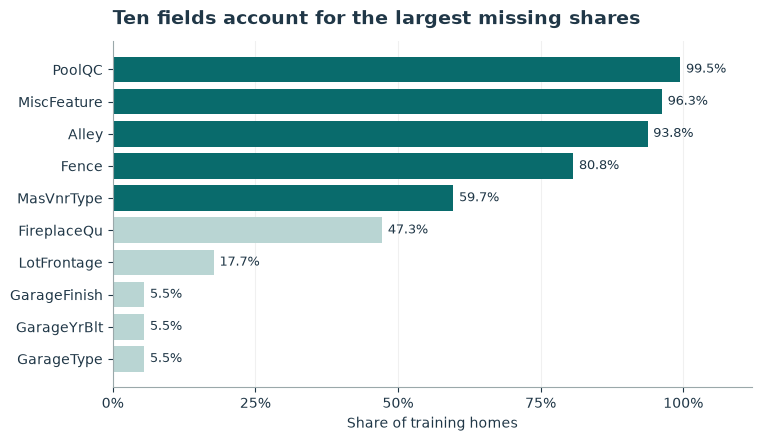

按数据字典，PoolQC、Alley 和 Fence 缺失通常代表没有相应设施。LotFrontage 等数值字段另行处理。


In [4]:
missing = train.drop(columns=["Id", "SalePrice"]).isna().mean().mul(100).nlargest(10).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 4.3), layout="constrained")
bars = ax.barh(missing.index, missing, color=[TEAL if value > 50 else PALE for value in missing])
ax.bar_label(bars, labels=[f"{value:.1f}%" for value in missing], padding=4, fontsize=9)
ax.set(xlim=(0, 112), xlabel="Share of training homes", title="Ten fields account for the largest missing shares")
ax.set_xticks([0, 25, 50, 75, 100])
ax.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ax.grid(axis="x", alpha=0.18)
show_figure(fig, "02_missingness.png")
print("按数据字典，PoolQC、Alley 和 Fence 缺失通常代表没有相应设施。LotFrontage 等数值字段另行处理。")

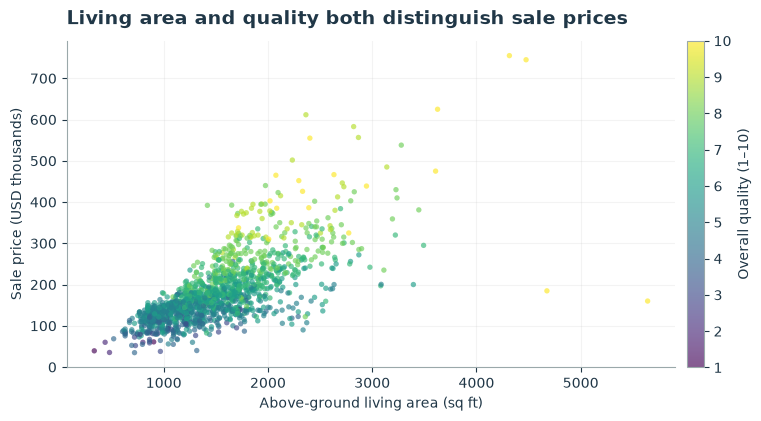

地上居住面积与价格的 Spearman 相关系数为 0.73。个别面积逾 4,000 平方英尺的低价交易也保留在验证中。


In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4.1), layout="constrained")
scatter = ax.scatter(train["GrLivArea"], price_k, c=train["OverallQual"], cmap="viridis",
                     s=15, alpha=0.65, edgecolors="none", rasterized=True)
colorbar = fig.colorbar(scatter, ax=ax, pad=.02)
colorbar.set_label("Overall quality (1–10)")
ax.set(xlabel="Above-ground living area (sq ft)", ylabel="Sale price (USD thousands)",
       title="Living area and quality both distinguish sale prices")
ax.grid(alpha=.15)
show_figure(fig, "03_area_and_price.png")
rho = train["GrLivArea"].corr(y, method="spearman")
print(f"地上居住面积与价格的 Spearman 相关系数为 {rho:.2f}。个别面积逾 4,000 平方英尺的低价交易也保留在验证中。")

## 原版模型与共同特征

三个对照沿用上一版配置。街区中位价由每个训练折计算，Ridge 使用独热编码，CatBoost 直接处理类别。模型只使用房屋和交易属性，编号仅用于核对。价格先取自然对数，输出时还原为美元。

In [6]:
CAT_COLS = train.drop(columns=["Id", "SalePrice"]).select_dtypes(exclude="number").columns.tolist() + ["MSSubClass"]
ABSENCE_FIELDS = {
    "Alley", "PoolQC", "Fence", "MiscFeature", "FireplaceQu", "MasVnrType", "BsmtQual", "BsmtCond",
    "BsmtExposure", "BsmtFinType1", "BsmtFinType2", "GarageType", "GarageFinish", "GarageQual", "GarageCond",
}


def make_features(frame):
    x = frame.drop(columns=["Id", "SalePrice"], errors="ignore").copy()
    x["HouseAge"] = (x["YrSold"] - x["YearBuilt"]).clip(lower=0)
    x["YearsSinceRemodel"] = (x["YrSold"] - x["YearRemodAdd"]).clip(lower=0)
    x["TotalInteriorSF"] = x["GrLivArea"] + x["TotalBsmtSF"]
    x["TotalBaths"] = x["FullBath"] + x["BsmtFullBath"] + 0.5 * (x["HalfBath"] + x["BsmtHalfBath"])
    porch_cols = ["OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch"]
    x["TotalPorchSF"] = x[porch_cols].sum(axis=1, min_count=len(porch_cols))
    for name in CAT_COLS:
        marker = "__ABSENT__" if name in ABSENCE_FIELDS else "__UNKNOWN__"
        x[name] = x[name].astype("string").fillna(marker).astype(str)
    for name in ("LotArea", "GrLivArea", "1stFlrSF", "TotalBsmtSF", "TotalInteriorSF", "LotFrontage"):
        x[name] = np.log1p(x[name])
    return x


X = make_features(train)
X_test = make_features(test)
assert X.columns.equals(X_test.columns)
NUM_COLS = [col for col in X.columns if col not in CAT_COLS]
BASE = "Neighborhood median"
LINEAR = "Ridge"
TREE = "CatBoost"


def make_estimator(name):
    if name == LINEAR:
        numbers = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
        prep = ColumnTransformer(
            [("num", numbers, NUM_COLS), ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS)],
            sparse_threshold=1.0,
        )
        return make_pipeline(prep, Ridge(alpha=20.0, solver="lsqr", tol=1e-7))
    if name == TREE:
        return CatBoostRegressor(iterations=1000, depth=5, learning_rate=.045, l2_leaf_reg=5,
                                 loss_function="RMSE", cat_features=CAT_COLS, random_seed=SEED,
                                 thread_count=4, verbose=False, allow_writing_files=False)
    raise ValueError(f"未定义的模型 {name}")


def fit_predict(name, fit_x, fit_y, predict_x):
    if name == BASE:
        medians = fit_y.groupby(fit_x["Neighborhood"]).median()
        values = predict_x["Neighborhood"].map(medians).fillna(fit_y.median()).to_numpy(dtype=float)
    else:
        estimator = make_estimator(name)
        estimator.fit(fit_x, np.log(fit_y))
        values = np.exp(estimator.predict(predict_x))
    if not (np.isfinite(values).all() and (values > 0).all()):
        raise ValueError(f"{name} 产生了无效价格。")
    return values

## 扩展特征与候选模型

质量等级保留顺序，面积与质量可以交互。我们还加入地上居住面积与已完工地下室面积之和、地下室完工比例及设施是否存在等特征。ElasticNet 用正则化限制系数，支持向量回归使用径向基核，改进版 CatBoost 使用 1,500 棵树，并对低基数类别应用独热编码。数值截尾和低频类别合并仅在适用模型的训练折内拟合。

参考了 GitHub 作者对等级编码、面积交互与不同模型融合的实现。此处保留所有成交记录，也保留所有极端房屋的验证分数。[特征构造源码](https://github.com/Jessi-Liu/house-prices-prediction/blob/7af2013f58ad8e59e4ea9772ffdcbc9691e7ba68/src/feature_engineering.py) · [模型融合案例](https://github.com/apoorva2121/ames-house-prices/blob/7fe1337e46d5578ced679668a3136ab73aeabd1e/README.md)

In [7]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import ElasticNet
from sklearn.svm import SVR

ENET = "ElasticNet+"
KERNEL = "SVR RBF"
TREEX = "CatBoost+"
SMOOTH = "Spline Ridge"
PAIR = "Blend 2"
TRIO = "Blend 3"
SMOOTH_PAIR = "Spline + tree"
SMOOTH_TRIO = "Spline + ElasticNet + tree"
SMOOTH_FULL = "Four-model blend"
MEMBERS = [ENET, KERNEL, TREEX, SMOOTH]
BLENDS = {
    PAIR: (ENET, TREEX),
    TRIO: (ENET, KERNEL, TREEX),
    SMOOTH_PAIR: (SMOOTH, TREEX),
    SMOOTH_TRIO: (SMOOTH, ENET, TREEX),
    SMOOTH_FULL: (SMOOTH, ENET, KERNEL, TREEX),
}
CANDIDATES = [BASE, LINEAR, TREE, *MEMBERS, *BLENDS]


def expanded_features(frame):
    """Add row-local attributes. Never learn from a validation or test distribution."""
    z = make_features(frame)
    new = {}
    rating = {label: level for level, label in enumerate(['Po', 'Fa', 'TA', 'Gd', 'Ex'], 1)}
    quality_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'KitchenQual',
                    'HeatingQC', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']
    for col in quality_cols:
        value = frame[col].map(rating)
        new[col + 'Rank'] = value.fillna(0) if col in ABSENCE_FIELDS else value
    orders = {'BsmtExposure': ['No', 'Mn', 'Av', 'Gd'],
              'GarageFinish': ['Unf', 'RFn', 'Fin'],
              'BsmtFinType1': ['Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
              'Functional': ['Sal', 'Sev', 'Maj2', 'Maj1', 'Mod', 'Min2', 'Min1', 'Typ']}
    for col, levels in orders.items():
        score = frame[col].map({name: i for i, name in enumerate(levels, 1)})
        new[col + 'Rank'] = score.fillna(0) if col in ABSENCE_FIELDS else score
    living = frame['GrLivArea']
    basement = frame['TotalBsmtSF']
    lower_finished = frame['BsmtFinSF1'] + frame['BsmtFinSF2']
    new['LogFinishedSF'] = np.log1p(living + lower_finished)
    new['BasementFinishedShare'] = (lower_finished / basement.where(basement.gt(0))).where(basement.ne(0), 0)
    new['QualityByLivingArea'] = (frame['OverallQual'] - 5) * np.log1p(living / 1000)
    new['QualityByTotalArea'] = (frame['OverallQual'] - 5) * np.log1p((living + basement) / 1000)
    new['QualityByCondition'] = (frame['OverallQual'] - 5) * (frame['OverallCond'] - 5)
    new['GarageAge'] = (frame['YrSold'] - frame['GarageYrBlt']).where(frame['GarageYrBlt'].le(frame['YrSold']))
    new['HasRemodel'] = frame['YearRemodAdd'].gt(frame['YearBuilt']).astype(int)
    for col in ['GarageArea', '2ndFlrSF', 'Fireplaces', 'TotalBsmtSF', 'PoolArea']:
        new['Has' + col] = frame[col].gt(0).astype(int)
    # More compact scales for highly variable counts, areas and amenity values.
    for col in ['MiscVal', 'PoolArea', 'MasVnrArea', 'OpenPorchSF', 'EnclosedPorch',
                'WoodDeckSF', 'ScreenPorch', '3SsnPorch', 'LowQualFinSF']:
        z[col] = np.log1p(frame[col])
    return pd.concat([z, pd.DataFrame(new, index=frame.index)], axis=1)

In [8]:
class FoldClipper(TransformerMixin, BaseEstimator):
    """Limit numeric extrapolation using the training split of the current fit."""
    def fit(self, X, y=None):
        table = pd.DataFrame(X)
        continuous = table.nunique().ge(20)
        self.lower_ = table.quantile(.005).where(continuous, -np.inf).to_numpy()
        self.upper_ = table.quantile(.995).where(continuous, np.inf).to_numpy()
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower_, self.upper_)


def advanced_estimator(name, columns):
    if name == SMOOTH:
        return make_spline_model(columns)
    if name == TREEX:
        return CatBoostRegressor(iterations=1500, depth=5, learning_rate=.035, l2_leaf_reg=5,
                                 one_hot_max_size=10, loss_function='RMSE', cat_features=CAT_COLS,
                                 random_seed=SEED, thread_count=4, verbose=False, allow_writing_files=False)
    numeric = [col for col in columns if col not in CAT_COLS]
    numeric_pipe = make_pipeline(SimpleImputer(strategy='median'), FoldClipper(), StandardScaler())
    categoricals = OneHotEncoder(min_frequency=5, handle_unknown='infrequent_if_exist')
    preparation = ColumnTransformer([('num', numeric_pipe, numeric), ('cat', categoricals, CAT_COLS)],
                                    sparse_threshold=1.0)
    if name == ENET:
        model = ElasticNet(alpha=.00055, l1_ratio=.70, max_iter=20000, tol=.00005, selection='cyclic')
    elif name == KERNEL:
        model = SVR(kernel='rbf', C=5.0, epsilon=.025, gamma=.0015, cache_size=256)
    else:
        raise ValueError(f'Unknown model: {name}')
    return make_pipeline(preparation, model)

### 让面积和房龄与价格呈曲线关系

样条回归允许价格随面积、房龄和质量的变化速度不同。它保留连续变量和类别变量，用折内训练残差给极端交易较小的拟合权重。验证时每套房权重都为一。每个融合方案对成员的**对数估价取等权平均**，等价于对美元估价取几何平均。[scikit-learn 样条回归示例](https://scikit-learn.org/stable/auto_examples/linear_model/plot_polynomial_interpolation.html)

In [9]:
from sklearn.base import RegressorMixin
from sklearn.preprocessing import SplineTransformer

class RobustRidge(RegressorMixin, BaseEstimator):
    """Ridge on log prices with Huber-style weights estimated on training rows."""
    def fit(self, X, y):
        self.ridge_ = Ridge(alpha=10.0, solver='lsqr', tol=1e-6)
        weights = np.ones(len(y))
        for step in range(5):
            self.ridge_.fit(X, y, sample_weight=weights)
            if step == 4:
                break
            residual = np.asarray(y) - self.ridge_.predict(X)
            scale = 1.4826 * np.median(np.abs(residual - np.median(residual)))
            cutoff = max(1.5 * scale, 1e-6)
            weights = np.minimum(1.0, cutoff / np.maximum(np.abs(residual), 1e-10))
        return self

    def predict(self, X):
        return self.ridge_.predict(X)


def make_spline_model(columns):
    smooth_columns = ['GrLivArea', 'TotalBsmtSF', 'TotalInteriorSF', 'LogFinishedSF',
                      'LotArea', 'HouseAge', 'YearsSinceRemodel', 'GarageArea',
                      'OverallCond', 'OverallQual', '1stFlrSF', 'YearBuilt']
    numeric = [c for c in columns if c not in CAT_COLS]
    linear_basis = make_pipeline(SimpleImputer(strategy='median'), FoldClipper(), StandardScaler())
    smooth_basis = make_pipeline(SimpleImputer(strategy='median'), FoldClipper(),
                                 SplineTransformer(n_knots=5, degree=2, knots='uniform',
                                                   include_bias=False, extrapolation='constant'),
                                 StandardScaler())
    prep = ColumnTransformer([('linear', linear_basis, numeric),
                              ('curves', smooth_basis, smooth_columns),
                              ('cat', OneHotEncoder(min_frequency=5, handle_unknown='infrequent_if_exist'), CAT_COLS)],
                             sparse_threshold=1.0)
    return make_pipeline(prep, RobustRidge())

In [10]:
def fit_component(name, training, target, scoring):
    if name in (BASE, LINEAR, TREE):
        return fit_predict(name, training, target, scoring)
    estimator = advanced_estimator(name, training.columns)
    estimator.fit(training, np.log(target))
    prediction = np.exp(estimator.predict(scoring))
    if not np.isfinite(prediction).all() or not (prediction > 0).all():
        raise ValueError(f'{name} returned an invalid estimate')
    return prediction


def blend_prices(outputs, names):
    return np.exp(np.log(np.stack([outputs[name] for name in names])).mean(axis=0))



def row_errors(actual, prediction):
    actual = np.asarray(actual, dtype=float)
    prediction = np.asarray(prediction, dtype=float)
    if actual.shape != prediction.shape or not np.isfinite(prediction).all() or not (prediction > 0).all():
        raise ValueError('预测结果的行数或数值不正确。')
    difference = prediction - actual
    return pd.DataFrame({
        'LogError': np.log(prediction) - np.log(actual),
        'ErrorUSD': difference,
        'AbsUSD': np.abs(difference),
        'APE_pct': 100 * np.abs(difference) / actual,
    })


def summarize(actual, prediction):
    delta = row_errors(actual, prediction)
    return {'LogRMSE': np.sqrt(delta.LogError.pow(2).mean()), 'MAE_USD': delta.AbsUSD.mean(),
            'MdAPE_pct': delta.APE_pct.median(), 'P90_APE_pct': delta.APE_pct.quantile(.9),
            'P90_AbsUSD': delta.AbsUSD.quantile(.9)}


def predict_models(components, training, scoring):
    # All preprocessing learned from data is fitted inside fit_component on these training rows.
    outputs = {}
    for name in components:
        fit_matrix, score_matrix = (X, X_test) if name in (BASE, LINEAR, TREE) else (expanded, expanded_test)
        score_rows = score_matrix if scoring is None else fit_matrix.iloc[scoring]
        outputs[name] = fit_component(name, fit_matrix.iloc[training], y.iloc[training], score_rows)
    return outputs


def predict_selection(name, training, scoring):
    components = BLENDS.get(name, (name,))
    forecasts = predict_models(components, training, scoring)
    return blend_prices(forecasts, components) if name in BLENDS else forecasts[name]


expanded = expanded_features(train)
expanded_test = expanded_features(test)
assert expanded.columns.equals(expanded_test.columns)
assert not {'Id', 'SalePrice'} & set(expanded.columns)

## 在同一批房屋上逐折比较

复用随机种子 42 的五折索引，每折训练 1,168 套、验证 292 套。并列的候选以事先列出的顺序打破平分。先选五折平均 Log RMSE 最低者，再做按年复核和最终全量训练。折间标准差以四为分母。

In [11]:
from concurrent.futures import ThreadPoolExecutor

splits = list(KFold(n_splits=5, shuffle=True, random_state=SEED).split(train))
folds = pd.Series(0, index=train.index, name='Fold')
oof = pd.DataFrame(index=train.index, columns=CANDIDATES, dtype=float)
components = [BASE, LINEAR, TREE, *MEMBERS]
# Each worker fits a distinct fold. Lower HOUSE_PRICES_JOBS to 1 on a small CPU.
jobs = max(1, min(5, int(os.environ.get('HOUSE_PRICES_JOBS', '2'))))


def fit_one_fold(pair):
    learn, valid = pair
    assert not np.intersect1d(learn, valid).size
    return predict_models(components, learn, valid)


with ThreadPoolExecutor(max_workers=jobs) as pool:
    for fold, ((learn, valid), forecasts) in enumerate(zip(splits, pool.map(fit_one_fold, splits)), 1):
        assert len(learn) == 1168 and len(valid) == 292 and folds.iloc[valid].eq(0).all()
        folds.iloc[valid] = fold
        for name, members in BLENDS.items():
            forecasts[name] = blend_prices(forecasts, members)
        for name, prediction in forecasts.items():
            oof.loc[valid, name] = prediction
        print(f'第 {fold} 折完成，验证 {len(valid)} 套。', flush=True)
assert folds.value_counts().sort_index().tolist() == [292] * 5
assert oof.notna().all().all() and np.isfinite(oof.to_numpy()).all() and oof.gt(0).all().all()

第 1 折完成，验证 292 套。


第 2 折完成，验证 292 套。


第 3 折完成，验证 292 套。


第 4 折完成，验证 292 套。


第 5 折完成，验证 292 套。


In [12]:
fold_rows, model_rows = [], []
for name in CANDIDATES:
    by_fold = row_errors(y, oof[name]).LogError.pow(2).groupby(folds).mean().pow(.5)
    for fold, score in by_fold.items():
        fold_rows.append({'Fold': fold, 'Model': name, 'ValidationRows': int(folds.eq(fold).sum()), 'LogRMSE': score})
    model_rows.append({'Model': name, 'MeanLogRMSE': by_fold.mean(), 'FoldSD': by_fold.std(ddof=1),
                       **summarize(y, oof[name])})
comparison = pd.DataFrame(model_rows).set_index('Model').rename(columns={'LogRMSE': 'OOFLogRMSE'})
fold_scores = pd.DataFrame(fold_rows)
comparison.to_csv(OUT / 'model_comparison.csv')
fold_scores.to_csv(OUT / 'fold_scores.csv', index=False)
pd.concat([train[['Id', 'SalePrice']], folds, oof], axis=1).to_csv(OUT / 'oof_predictions.csv', index=False)
winner = comparison.MeanLogRMSE.idxmin()
print(f'五折平均 Log RMSE 最低的方案为 {winner}。')
display(comparison.sort_values('MeanLogRMSE').round(5))
display(fold_scores.pivot(index='Fold', columns='Model', values='LogRMSE')[[TREE, winner]].round(6))

五折平均 Log RMSE 最低的方案为 Spline + ElasticNet + tree。


,MeanLogRMSE,FoldSD,OOFLogRMSE,MAE_USD,MdAPE_pct,P90_APE_pct,P90_AbsUSD
Model,,,,,,,
Spline + ElasticNet + tree,0.11819,0.02058,0.11961,13532.85112,5.00277,15.35917,27485.55154
Spline + tree,0.11821,0.02106,0.11970,13566.76018,4.85145,15.69817,27873.02611
Four-model blend,0.11872,0.02041,0.12012,13436.54396,4.97529,15.07641,27441.78597
Blend 2,0.11978,0.01897,0.12097,13855.51466,5.06965,15.80702,28691.90183
Blend 3,0.11996,0.01941,0.12121,13588.63775,5.01320,15.37080,27953.09521
Spline Ridge,0.12059,0.02517,0.12268,13605.33331,5.11915,15.68143,28710.82479
CatBoost+,0.12311,0.01753,0.12410,14671.03473,5.29506,16.72406,31036.43082
ElasticNet+,0.12396,0.01918,0.12514,14491.04576,5.16119,16.54410,28603.14781
CatBoost,0.12535,0.01698,0.12626,14858.86791,5.57985,16.60901,28820.39655


Model,CatBoost,Spline + ElasticNet + tree
Fold,,
1,0.130877,0.122798
2,0.111454,0.104859
3,0.150087,0.151577
4,0.126746,0.112029
5,0.107571,0.099662


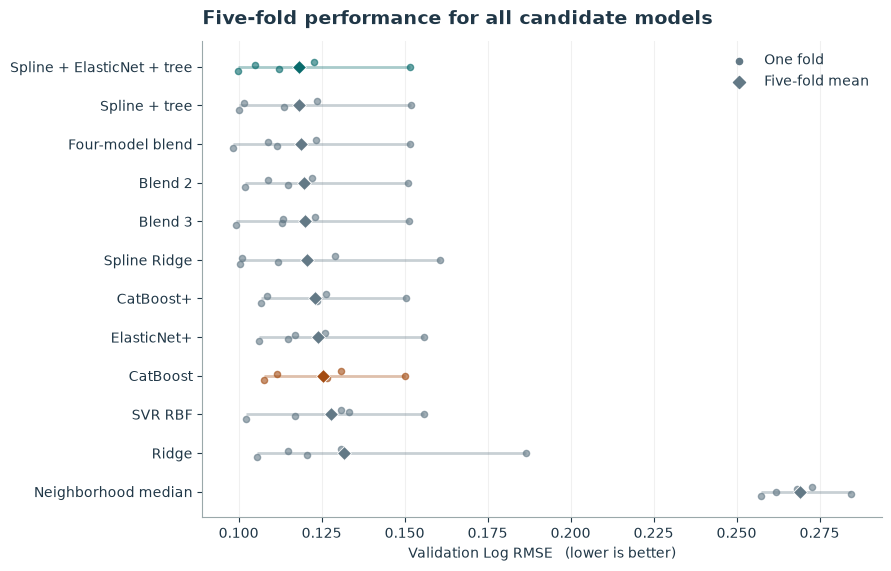

In [13]:
fig, ax = plt.subplots(figsize=(8.8, 5.6), layout='constrained')
ordered = comparison.sort_values('MeanLogRMSE').index
for row, name in enumerate(ordered):
    scores = fold_scores.loc[fold_scores.Model.eq(name), 'LogRMSE'].to_numpy()
    color = TEAL if name == winner else (AMBER if name == TREE else MUTED)
    ax.hlines(row, scores.min(), scores.max(), color=color, alpha=.35, lw=2)
    ax.scatter(scores, row + np.linspace(-.11, .11, len(scores)), color=color, s=20, alpha=.60)
    ax.scatter(comparison.loc[name, 'MeanLogRMSE'], row, marker='D', color=color, edgecolors='white', lw=.6, s=50, zorder=3)
ax.set(yticks=range(len(ordered)), yticklabels=ordered, xlabel='Validation Log RMSE   (lower is better)',
       title='Five-fold performance for all candidate models')
ax.invert_yaxis()
ax.grid(axis='x', alpha=.18)
ax.scatter([], [], color=MUTED, s=20, label='One fold')
ax.scatter([], [], color=MUTED, s=38, marker='D', label='Five-fold mean')
ax.legend(loc='upper right', frameon=False)
show_figure(fig, '04_model_comparison.png')

## 折外误差和失败样本

百分比误差以真实成交价为分母。正残差代表高估，负残差代表低估。第 90 百分位线性插值得出。表中既比较各版本自己的最差一成，也把上一版最差一成的房屋固定下来，逐房比较前后变化。

In [14]:
details = train[['Id', 'SalePrice', 'Neighborhood', 'GrLivArea', 'OverallQual', 'SaleCondition']].copy()
details['Fold'] = folds
details['OldPrediction'] = oof[TREE]
details['NewPrediction'] = oof[winner]
old_delta = row_errors(y, oof[TREE])
new_delta = row_errors(y, oof[winner])
for tag, delta in [('Old', old_delta), ('New', new_delta)]:
    for field in ['APE_pct', 'AbsUSD', 'ErrorUSD']:
        details[tag + field] = delta[field]
old_tail = details.OldAPE_pct.gt(details.OldAPE_pct.quantile(.9))
new_tail = details.NewAPE_pct.gt(details.NewAPE_pct.quantile(.9))
details['InOldWorstDecile'] = old_tail
details['InNewWorstDecile'] = new_tail
details.sort_values('NewAPE_pct', ascending=False).to_csv(OUT / 'house_errors.csv', index=False)
print(f'按新版绝对百分比误差选出的 {new_tail.sum()} 套难例中，'
      f'中位百分比误差为 {details.loc[new_tail, "NewAPE_pct"].median():.2f}%，'
      f'中位美元误差为 ${details.loc[new_tail, "NewAbsUSD"].median():,.0f}。')
print(f'固定旧版最难的 {old_tail.sum()} 套，'
      f'其中 {details.loc[old_tail, "NewAPE_pct"].lt(details.loc[old_tail, "OldAPE_pct"]).sum()} 套百分比误差缩小。')
columns = ['Id', 'Fold', 'SalePrice', 'OldPrediction', 'NewPrediction', 'NewErrorUSD', 'OldAPE_pct', 'NewAPE_pct']
display(details.nlargest(5, 'NewAPE_pct')[columns].round(2))

按新版绝对百分比误差选出的 146 套难例中，中位百分比误差为 21.48%，中位美元误差为 $33,641。
固定旧版最难的 146 套，其中 111 套百分比误差缩小。


,Id,Fold,SalePrice,OldPrediction,NewPrediction,NewErrorUSD,OldAPE_pct,NewAPE_pct
1298,1299,3,160000,519730.74,665850.20,505850.20,224.83,316.16
523,524,3,184750,637293.10,623758.60,439008.60,244.95,237.62
30,31,1,40000,89790.32,90988.83,50988.83,124.48,127.47
632,633,5,82500,176224.31,181548.65,99048.65,113.61,120.06
462,463,2,62383,121540.52,125231.08,62848.08,94.83,100.75


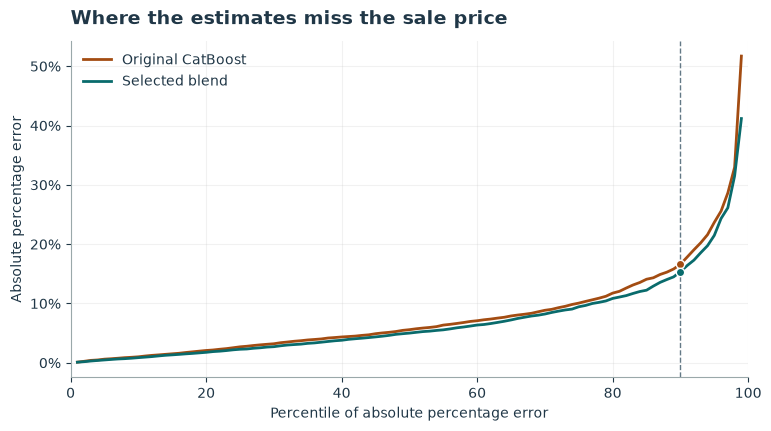

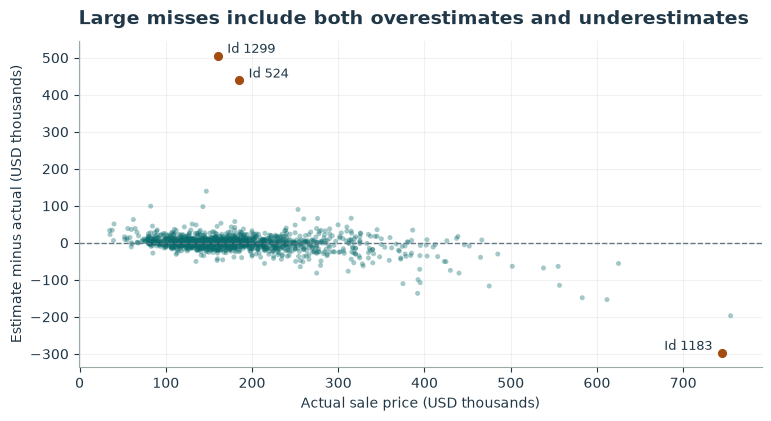

In [15]:
# Include the dollar and percentile thresholds without truncating the most difficult observations.
fig, ax = plt.subplots(figsize=(7.6, 4.2), layout='constrained')
levels = np.arange(1, 100)
for delta, color, label in [(old_delta, AMBER, 'Original CatBoost'), (new_delta, TEAL, 'Selected blend' if winner in BLENDS else winner)]:
    q = np.percentile(delta.APE_pct, levels)
    ax.plot(levels, q, lw=2, color=color, label=label)
    ax.scatter([90], [q[89]], color=color, edgecolors='white', zorder=4)
ax.axvline(90, color=MUTED, lw=1, linestyle='--')
ax.set(xlim=(0, 100), xlabel='Percentile of absolute percentage error', ylabel='Absolute percentage error',
       title='Where the estimates miss the sale price')
ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ax.grid(alpha=.17)
ax.legend(frameon=False, loc='upper left')
show_figure(fig, '05_error_percentiles.png')

fig, ax = plt.subplots(figsize=(7.6, 4.1), layout='constrained')
actual_k = y / 1000
residual_k = new_delta.ErrorUSD / 1000
ax.scatter(actual_k, residual_k, s=13, color=TEAL, alpha=.37, edgecolors='none')
ax.axhline(0, color=MUTED, lw=1, linestyle='--')
highlight = details.NewErrorUSD.nlargest(2).index.tolist() + [details.NewErrorUSD.idxmin()]
for i in dict.fromkeys(highlight):
    ax.scatter(actual_k.iloc[i], residual_k.iloc[i], s=31, color=AMBER, zorder=3)
    left = actual_k.iloc[i] >= 500
    ax.annotate(f'Id {train.Id.iloc[i]}', (actual_k.iloc[i], residual_k.iloc[i]),
                xytext=(-7 if left else 7, 2), textcoords='offset points', ha='right' if left else 'left', fontsize=9)
ax.set(xlabel='Actual sale price (USD thousands)', ylabel='Estimate minus actual (USD thousands)',
       title='Large misses include both overestimates and underestimates')
ax.grid(alpha=.17)
show_figure(fig, '06_residuals.png')

## 按成交年复核

锁定五折优胜方案后，用 2006–2009 年训练，此次拟合只读取这些年份的标签。对 2010 年的每套房生成预测，和同一时段重训的原版 CatBoost 对比。2010 年样本也参加过前面的随机五折选型，解读这项检查时需要考虑样本重叠。

In [16]:
history = np.flatnonzero(train.YrSold.lt(2010))
year_2010 = np.flatnonzero(train.YrSold.eq(2010))
assert train.YrSold.iloc[history].max() < train.YrSold.iloc[year_2010].min()
assert len(history) + len(year_2010) == len(train)
chrono = train.iloc[year_2010][['Id', 'YrSold', 'SalePrice']].reset_index(drop=True)
results_2010 = []
for name in dict.fromkeys([TREE, winner]):
    chrono[name] = predict_selection(name, history, year_2010)
    results_2010.append({'Model': name, 'TrainingRows': len(history), 'ValidationRows': len(chrono),
                         **summarize(chrono.SalePrice, chrono[name])})
chronological = pd.DataFrame(results_2010).set_index('Model')
chronological.to_csv(OUT / 'validation_2010.csv')
chrono.to_csv(OUT / 'predictions_2010.csv', index=False)
display(chronological.round(5))

,TrainingRows,ValidationRows,LogRMSE,MAE_USD,MdAPE_pct,P90_APE_pct,P90_AbsUSD
Model,,,,,,,
CatBoost,1285,175,0.11814,15148.34014,6.68021,20.33093,28580.95377
Spline + ElasticNet + tree,1285,175,0.10702,13792.17912,5.99458,17.27371,26531.50151


## 全量重训并生成提交

用全部 1,460 套竞赛训练房屋重新拟合胜者的各个成员，按比赛样表的编号顺序保存测试房屋的预测，并从磁盘回读核对。

In [17]:
full_prediction = predict_selection(winner, np.arange(len(train)), scoring=None)
price_by_id = pd.Series(full_prediction, index=test.Id)
submission = pd.DataFrame({'Id': sample.Id, 'SalePrice': sample.Id.map(price_by_id)})
submission.to_csv(OUT / 'submission.csv', index=False, float_format='%.2f', lineterminator='\n')
submitted = pd.read_csv(OUT / 'submission.csv')
assert list(submitted) == ['Id', 'SalePrice'] and submitted.Id.equals(sample.Id)
assert len(submitted) == submitted.Id.nunique() == 1459
assert np.isfinite(submitted.SalePrice).all() and submitted.SalePrice.gt(0).all()
np.testing.assert_allclose(submitted.SalePrice, full_prediction, rtol=0, atol=.005001)
print(f'已按样表顺序生成 {len(submitted):,} 行，价格已四舍五入至美分。')
display(submitted.head())

已按样表顺序生成 1,459 行，价格已四舍五入至美分。


,Id,SalePrice
0,1461,120502.09
1,1462,160096.70
2,1463,186375.84
3,1464,198392.52
4,1465,192111.47


## 适用范围与复现

数据记录的是美国爱荷华州 Ames 的历史成交。稀有房屋、特殊交易和年份差异都可能影响误差。模型使用部分交易时字段，提前估价时应按实际可用的信息重新评估。随机五折用于候选比较和选优，报告分数可能略为乐观。排行榜成绩以参赛账号正式提交后返回的结果为准。